In [8]:
from glob import glob

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from toolbox import evaluate_combinations, get_freqs, visualize_Category_hist
from toolbox.loading import load_data
from toolbox.visualization import cmap_gradient

# Data statistics

In [16]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    _,
    LesionAssessment,
    label_healthy_vs_cancer,
    label_healthy_vs_hbd,
    label_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


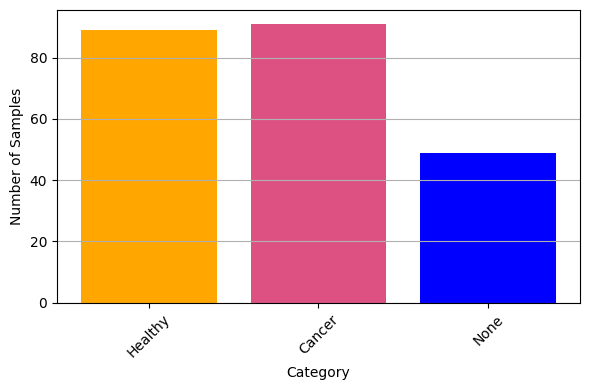

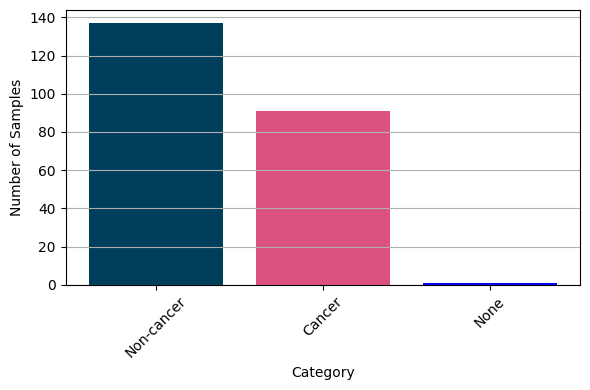

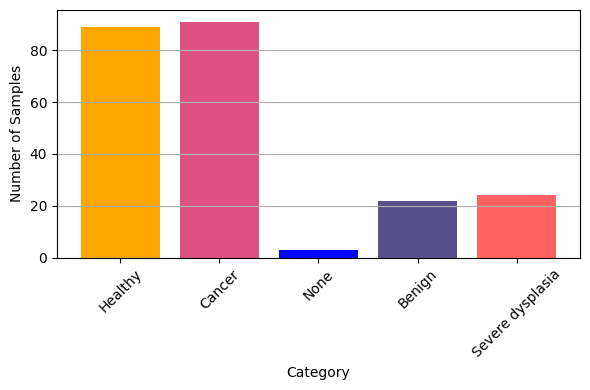

In [17]:
visualize_Category_hist(label_healthy_vs_cancer)
visualize_Category_hist(label_healthy_vs_hbd)
visualize_Category_hist(label_MC)

# Frequency reduction

In [54]:
class_task = "healthy_vs_cancer"
class_task = "cancer_vs_hbd"
class_task = "MC"

In [55]:
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
fold_rankings_baseline = tmp["fold_rankings_baseline"]
aucs_baseline = tmp["aucs_baseline"]
top_freqs_baseline = tmp["top_freqs_baseline"]
fold_aucs_baseline = tmp["fold_aucs_baseline"].tolist()

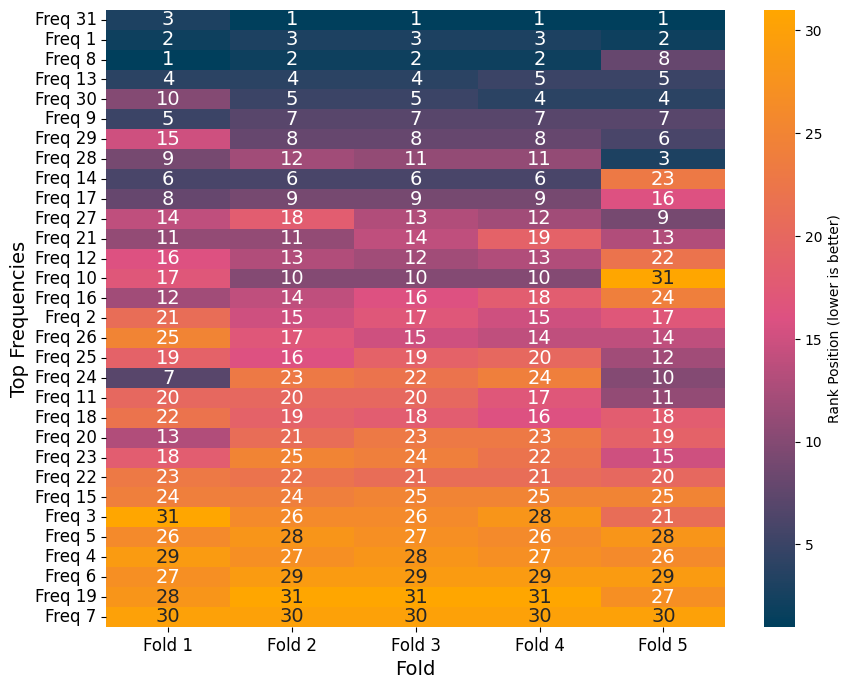

In [56]:
def plot_fold_rankings(fold_rankings_dict, top_n_freqs=20, class_task="unnamed"):
    """
    Visualizes fold frequency rankings as heatmaps for multiple ranking sets.

    Parameters:
        fold_rankings_dict : dict
            Dictionary where keys are method names and values are lists of np.arrays (fold rankings).
        top_n_freqs : int
            Number of top composite frequencies to display in the heatmap.
    """
    for name, rankings in fold_rankings_dict.items():
        n_folds = len(rankings)
        n_freqs = len(rankings[0])

        # Composite ranking across folds for sorting
        score_accumulator = np.zeros(n_freqs)
        for fold in rankings:
            for rank, freq_idx in enumerate(fold):
                score_accumulator[freq_idx] += n_freqs - rank

        composite_ranking = np.argsort(score_accumulator)[::-1][:top_n_freqs]

        # Create rank matrix: rows = top freqs, cols = folds
        rank_matrix = np.full((top_n_freqs, n_folds), np.nan)
        for f_idx, fold in enumerate(rankings):
            for i, freq in enumerate(composite_ranking):
                pos = np.where(fold == freq)[0]
                if pos.size > 0:
                    rank_matrix[i, f_idx] = pos[0] + 1  # +1 for 1-based rank

        plt.figure(figsize=(9, 7))
        sns.heatmap(
            rank_matrix,
            annot=True,
            fmt=".0f",
            cmap=cmap_gradient,
            cbar_kws={"label": "Rank Position (lower is better)"},
            xticklabels=[f"Fold {i+1}" for i in range(n_folds)],
            yticklabels=[f"Freq {f+1}" for f in composite_ranking],
            annot_kws={"fontsize": 14},
        )
        plt.xlabel("Fold", fontsize=14)
        plt.ylabel("Top Frequencies", fontsize=14)

        plt.xticks(fontsize=12)  # rotate if needed
        plt.yticks(fontsize=12)
        plt.tight_layout()
        plt.savefig(
            f"results/Fold-wise_frequency_impact_rankings_{name}_{class_task}.pdf",
            bbox_inches="tight",
        )
        plt.show()


fold_rankings_dict = {
    "Baseline": fold_rankings_baseline,
    # "Long-across": fold_rankings_la,
    # "Long-across extend": fold_rankings_lae,
    # "Skip 1": fold_rankings_s1,
}

plot_fold_rankings(fold_rankings_dict, top_n_freqs=31, class_task=class_task)

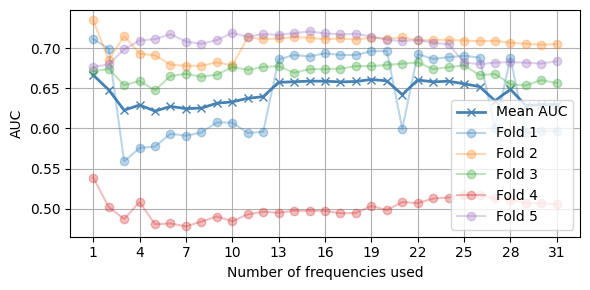

In [57]:
# Plot AUC vs number of frequencies
plt.figure(figsize=(6, 3))
plt.plot(
    range(1, 31 + 1),
    np.nanmean([np.array(v) for v in fold_aucs_baseline.values()], axis=0),
    marker="x",
    color="steelblue",
    linewidth=2,
    label="Mean AUC",
)

# Add individual fold lines
for fold_idx in range(5):
    plt.plot(
        range(1, 31 + 1),
        fold_aucs_baseline[fold_idx],
        "o-",
        alpha=0.3,
        label=f"Fold {fold_idx+1}",
    )

plt.xlabel("Number of frequencies used")
plt.xticks(range(1, 31 + 1,3))
plt.ylabel("AUC")
plt.grid(True)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"results/baselineaucs_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [58]:
freq_idx, freq_list = get_freqs(plot=False)

In [59]:
top_2 = top_freqs_baseline[:2]
top_3 = top_freqs_baseline[:3]
top_5 = top_freqs_baseline[:5]
top_12 = top_freqs_baseline[:12]

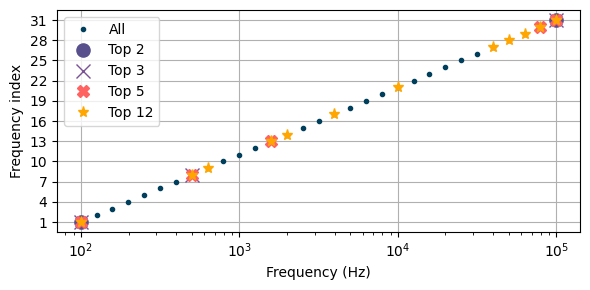

In [60]:
plt.figure(figsize=(6, 3))
plt.plot(freq_list[freq_idx], freq_idx+1, ".", c="#003F5C", ms=6, label="All")
plt.plot(freq_list[top_2], top_2+1, "o", c="#58508D", ms=9.5, label="Top 2")
plt.plot(freq_list[top_3], top_3+1, "x", c="#7A5195", ms=9.5, label="Top 3")
plt.plot(freq_list[top_5], top_5+1, "X", c="#FF6361", ms=8, label="Top 5")
plt.plot(freq_list[top_12], top_12+1, "*", c="#FFA600", ms=8, label="Top 12")
plt.legend()
plt.grid()
plt.xlabel("Frequency (Hz)")
plt.yticks(range(1, 31 + 1,3))
plt.xscale("log")
plt.ylabel("Frequency index")
plt.tight_layout()
plt.savefig(f"results/freq_topX_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [61]:
df_results = pd.read_csv(f"results/freq-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/freq-analysis_{class_task}_params.csv")

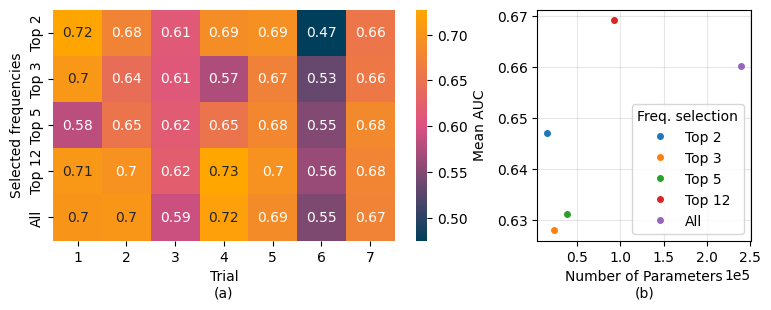

In [36]:
df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "Mean AUC"}, ax=ax0
)
ax0.set_ylabel("Selected frequencies")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Mean AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Fsel"],
        markersize=8,
    )
ax1.set_xlabel("Number of Parameters\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
# ax1.set_xscale('log')

ax1.legend(title="Freq. selection")
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [37]:
df_plot

,Fsel,n_params,avg. ROC AUC
0,Top 2,15456,0.646949
1,Top 3,23184,0.628001
2,Top 5,38640,0.631165
3,Top 12,92736,0.669221
4,All,239568,0.660275


In [38]:
df_plot["n_params"] / 239568 * 100

0      6.451613
1      9.677419
2     16.129032
3     38.709677
4    100.000000
Name: n_params, dtype: float64

In [39]:
min(df_plot["avg. ROC AUC"]), max(df_plot["avg. ROC AUC"])

(0.6280013499788709, 0.6692210117027318)

# IIVV pattern reduction

| Mask Task 1     | Mean AUC | Masks Task 2    | Mean AUC | Mask Task 3     | Mean AUC |
|-----------------|----------|-----------------|----------|-----------------|----------|
| Skip1 medium    | 0.898305 | Skip1 far       | 0.834155 | Adj. far        | 0.692485 |
| Skip1 far       | 0.897303 | Opp. medium     | 0.830018 | Med. a+ ext.    | 0.684450 |
| Opp. medium     | 0.893775 | Opp. far        | 0.816908 | Opp. far        | 0.672589 |
| Med. adj.       | 0.893131 | Skip1 medium    | 0.816241 | Skip1 far       | 0.666939 |
| Adj. far        | 0.890896 | Med. adj.       | 0.816052 | Opp. medium     | 0.659665 |
| Opp. far        | 0.883538 | Adj. far        | 0.815177 | Med. adj.       | 0.658376 |
| Adj. close      | 0.882748 | Skip1 close     | 0.814272 | Opp. close      | 0.656658 |
| All             | 0.880814 | Long a+         | 0.813387 | Skip1 medium    | 0.651982 |
| Skip1 close     | 0.873721 | All             | 0.812316 | All             | 0.647114 |
| Opp. close      | 0.871697 | Adj. close      | 0.812081 | Skip1 close     | 0.636404 |
| Long a+ ext.    | 0.865944 | Med. a+ ext.    | 0.811729 | Adj. close      | 0.618054 |
| Med. a+ ext.    | 0.863432 | Long a+ ext.    | 0.808150 | Long a+ ext.    | 0.585852 |
| Long a+         | 0.854724 | Opp. close      | 0.806073 | Long a+         | 0.549452 |

In [50]:
class_task = "healthy_vs_cancer"
class_task = "cancer_vs_hbd"
class_task = "MC"

In [51]:
df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params.csv")

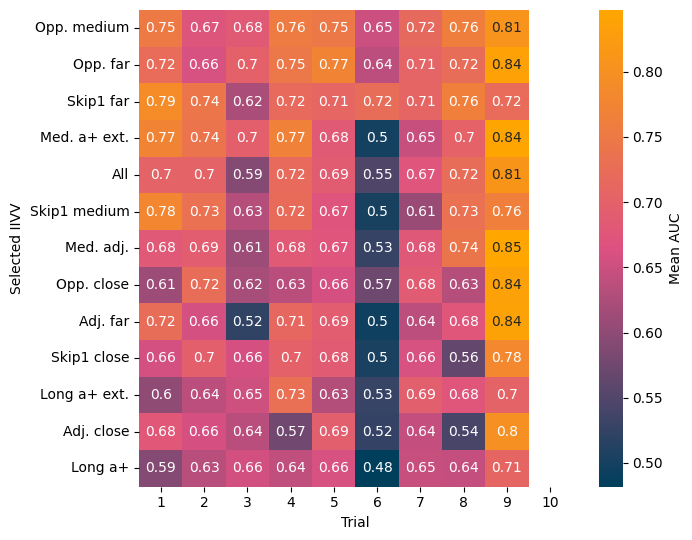

In [52]:
# --- Heatmap figure ---
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

mask_means = df_pivot.mean(axis=1)
# Sort descending by mean ROC AUC
order = mask_means.sort_values(ascending=False).index.tolist()
df_pivot = df_pivot.reindex(order)

fig1, ax0 = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    df_pivot,
    annot=True,
    cmap=cmap_gradient,
    cbar_kws={"label": "Mean AUC"},
    ax=ax0,
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial")
plt.tight_layout()
plt.savefig(f"results/IIVV_sel_heatmap_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [53]:
print("Ranked by best preformance")
print(mask_means[order])

Ranked by best preformance
Mask
Opp. medium     0.726803
Opp. far        0.722466
Skip1 far       0.722053
Med. a+ ext.    0.705660
All             0.684185
Skip1 medium    0.682611
Med. adj.       0.681481
Opp. close      0.663889
Adj. far        0.661297
Skip1 close     0.656079
Long a+ ext.    0.649537
Adj. close      0.639078
Long a+         0.628847
dtype: float64


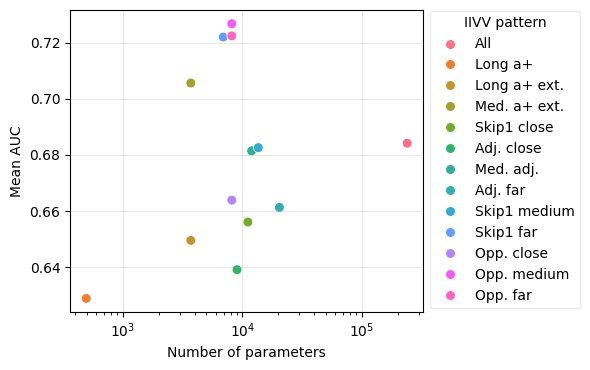

In [54]:
fig2, ax1 = plt.subplots(figsize=(6, 3.8))
sns.scatterplot(
    data=df_plot,
    x="n_params",
    y="avg. ROC AUC",
    hue="Mask",
    # palette="dark:salmon_r",
    s=50,
    ax=ax1,
)
ax1.set_xscale("log")
ax1.set_xlabel("Number of parameters")
ax1.set_ylabel("Mean AUC")
ax1.grid(alpha=0.3)
ax1.legend(
    title="IIVV pattern", framealpha=0.4, bbox_to_anchor=(1, 1.02), loc="upper left"
)

plt.tight_layout()
plt.savefig(f"results/IIVV_sel_scatter_{class_task}.pdf", bbox_inches="tight")
plt.show()

# Model and parameter tuning

## Tuning: 4 (best freq. sel) x 4 (best IIVV sel.) = 16 combinations

## Parameter tuning: SVM, RF, LR for baseline

The unaugmented data $\{\mathbf{X},\mathbf{Y}\}_{n}^{N-1}$ for the best IIVV pattern and best 

___

# Results

In [4]:
import glob

import numpy as np
import pandas as pd
from toolbox.evaluation import load_top_Fsel_Msel

In [5]:
csv_files = glob.glob("results/LPOCV_tuning_*.csv")

if not csv_files:
    print("No matching file name found.")
else:
    for file in csv_files:
        try:
            df = pd.read_csv(file)
            print(f"{file}: {len(df)} Zeilen")
        except Exception as e:
            print(f"Error during loading {file}: {e}")

results/LPOCV_tuning_SVM_healthy_vs_cancer.csv: 160 Zeilen
results/LPOCV_tuning_SVM_cancer_vs_hbd.csv: 160 Zeilen
results/LPOCV_tuning_RF_healthy_vs_cancer.csv: 160 Zeilen
results/LPOCV_tuning_LR_healthy_vs_cancer.csv: 160 Zeilen
results/LPOCV_tuning_RF_cancer_vs_hbd.csv: 160 Zeilen
results/LPOCV_tuning_LR_cancer_vs_hbd.csv: 160 Zeilen
results/LPOCV_tuning_SVM_MC.csv: 160 Zeilen
results/LPOCV_tuning_RF_MC.csv: 160 Zeilen
results/LPOCV_tuning_LR_MC.csv: 160 Zeilen


In [6]:
tasks = ["healthy_vs_cancer", "cancer_vs_hbd", "MC"]
models = ["SVM", "RF", "LR"]

for class_task in tasks:
    # load frequency selection
    Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)

    for model in models:
        if model == models[0]:
            param_grid = {
                "kernel": ["linear", "poly", "rbf", "sigmoid"],
                "C": np.logspace(
                    -3, 3, 7, dtype=float
                ),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
            }

        elif model == models[1]:
            param_grid = {
                "n_estimators": [100, 300, 500, 800],
                "max_depth": [510, 20, None],
                "max_features": ["sqrt", "log2"],
                "min_samples_split": [2, 5, 10],
                "min_samples_leaf": [1, 2, 4],
            }
        elif model == models[2]:
            param_grid = {
                "C": [0.01, 0.1, 1, 10, 100],
                "max_iter": [100, 1000, 10_000],
            }
        keys = list(param_grid.keys())

        print("\n%----------------------------%")
        print(f"\t{class_task}")
        print(f"\t{model}")

        df = pd.read_csv(f"results/LPOCV_tuning_{model}_{class_task}.csv")

        print("Top Frequencies")
        for Fsel, val in Freq_sel.items():
            print("\t", Fsel, ":", val)
        print("Top IIVVs")
        for Msel in Mask_sel.keys():
            print("\t", Msel)
        print("\n")
        df["hpt_combinations"] = df.apply(
            lambda row: "_".join([str(row[k]) for k in keys]), axis=1
        )

        df["Fsel_Msel"] = df.apply(
            lambda row: "_".join([str(row[k]) for k in ["Fsel", "Msel"]]), axis=1
        )

        result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
        print(result)

        for col in ["hpt_combinations"]:
            print(f"\nColumn: {col}")
            print(df[col].value_counts())

        # get most important tuning comb
        top_hpt = df["hpt_combinations"].value_counts().idxmax()
        print(f"\nMost counted hpt_combinations: {top_hpt}")

        fsel_msel_counts = (
            df.loc[df["hpt_combinations"] == top_hpt, "Fsel_Msel"]
            .value_counts()
            .reset_index()
            .rename(columns={"index": "Fsel_Msel", "Fsel_Msel": "count"})
        )

        print(f"\nRelated Fsel_Msel etries for {top_hpt}")
        print(fsel_msel_counts)

        print("%----------------------------%")


%----------------------------%
	healthy_vs_cancer
	SVM
Top Frequencies
	 Top 2 : [30  0]
	 Top 3 : [30  0 27]
	 Top 5 : [30  0 27 12 29]
	 Top 12 : [30  0 27 12 29 28 13 16 20  8 26 23]
Top IIVVs
	 Med. adj.
	 Skip1 medium
	 Skip1 far
	 Opp. medium


   hpt_combinations   val AUC
0      linear_0.001  0.884116
1       linear_0.01  0.881203
2        linear_0.1  0.877465
3         poly_0.01  0.889859
4          poly_0.1  0.873550
5          poly_1.0  0.891842
6           rbf_0.1  0.882165
7           rbf_1.0  0.882267
8          rbf_10.0  0.891845
9         rbf_100.0  0.897612
10       rbf_1000.0  0.881985
11      sigmoid_0.1  0.886454

Column: hpt_combinations
hpt_combinations
rbf_1.0         43
rbf_10.0        43
linear_0.01     20
linear_0.001    19
poly_0.01        9
sigmoid_0.1      9
linear_0.1       5
poly_1.0         5
poly_0.1         3
rbf_100.0        2
rbf_1000.0       1
rbf_0.1          1
Name: count, dtype: int64

Most counted hpt_combinations: rbf_1.0

Related Fsel_Msel et

## Pattern and Parameters

In [63]:
from toolbox.evaluation import load_top_Fsel_Msel

In [64]:
class_tasks = ["healthy_vs_cancer","cancer_vs_hbd","MC"]

for class_task in class_tasks:
    print(class_task,"\n")
    Freq_sel,_ = load_top_Fsel_Msel(class_task)
    print(Freq_sel['Top 12']+1)

healthy_vs_cancer 

[31  1 28 13 30 29 14 17 21  9 27 24]
cancer_vs_hbd 

[31  1 13 30  8  9 14 12 17 28 29 27]
MC 

[31  1  8 13 30  9 29 28 14 17 27 21]


___